<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

**公司名称：贵州茅台酒股份有限公司，股票代码：600519.SH**

贵州茅台是国内白酒行业龙头上市公司，主营茅台酒及系列酒的生产与销售，产品具备强品牌壁垒，盈利能力稳定，现金流充沛，是A股经典蓝筹股。
本次作业借助Tushare接口，采集贵州茅台2015-2024年年报财务数据与年末股票行情数据，开展基本面与股价的数据分析。

# 第二部分：研究问题题目及其内涵介绍


### 研究问题
贵州茅台年度扣非净利润与年末股票收盘价，是否存在显著正相关关系？

### 内涵介绍
扣非净利润代表企业主营业务真实盈利水平。基本面理论认为，企业盈利增长会支撑公司股价长期上行。
本研究利用Tushare采集贵州茅台2015至2024年的年报扣非净利润、每年年末交易日收盘价，计算相关系数并可视化，验证盈利基本面与二级市场股价的联动关系。
> 说明：相关性不等于因果，股价还会受到宏观环境、市场情绪、资金面等因素干扰。

# 第三部分：数据采集

In [12]:
import pandas as pd
import tushare as ts

# ========== 0. 设置 Tushare Token ==========
# ⚠️ 注意：请将下面的 token 替换为你自己的 Token（你截图里的已泄露，建议去官网重置）
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token)
pro = ts.pro_api()

# ========== 1. 获取贵州茅台年报财务指标 (扣非净利润) ==========
finance_df = pro.fina_indicator(ts_code='600519.SH', start_date='20150101', end_date='20241231')

# 【修正报错点】仅保留年报 (end_date 以 1231 结尾，替代原先错误的 'end_type' 筛选)
finance_year = finance_df[finance_df['end_date'].str.endswith('1231')].copy()

# 提取年份、扣非净利润
finance_year['year'] = pd.to_datetime(finance_year['end_date']).dt.year
profit_df = finance_year[['year', 'profit_dedt']].rename(columns={'profit_dedt': '扣非净利润(万元)'}).reset_index(drop=True)

print("=====贵州茅台年度扣非净利润数据====")
print(profit_df)

# ========== 2. 获取每年【最后一个交易日】收盘价 ==========
price_list = []

for year in range(2015, 2025):
    # 获取每年12月份的交易日数据，然后取最后一行即为该年最后一个交易日
    start_date = f"{year}1201"
    end_date = f"{year}1231"
    
    # 调用 daily 接口获取行情数据
    df_price = pro.daily(ts_code='600519.SH', start_date=start_date, end_date=end_date)
    
    if not df_price.empty:
        # Tushare 返回的数据通常按日期降序排列，取第一行即为该年最后一个交易日
        last_day_data = df_price.iloc[0]
        price_list.append({
            'year': year,
            'close_price': last_day_data['close']
        })
    else:
        print(f"警告：未获取到 {year} 年的行情数据")

# 将列表转换为 DataFrame
price_df = pd.DataFrame(price_list)

print("\n=====贵州茅台每年最后一个交易日收盘价====")
print(price_df)

# ========== 3. 合并财务数据与价格数据 ==========
# 按照年份进行合并
final_df = pd.merge(profit_df, price_df, on='year', how='inner')

# 调整列顺序，方便查看
final_df = final_df[['year', '扣非净利润(万元)', 'close_price']]

print("\n=====合并后的最终数据====")
print(final_df)

# (可选) 导出为 Excel 或 CSV 文件方便提交作业
# final_df.to_excel('贵州茅台年度数据.xlsx', index=False)

=====贵州茅台年度扣非净利润数据====
    year     扣非净利润(万元)
0   2024  8.624091e+10
1   2023  7.475256e+10
2   2022  6.279187e+10
3   2022  6.279187e+10
4   2021  5.258110e+10
5   2021  5.258110e+10
6   2020  4.701642e+10
7   2020  4.701642e+10
8   2019  4.140691e+10
9   2019  4.140691e+10
10  2018  3.558544e+10
11  2018  3.558544e+10
12  2017  2.722408e+10
13  2017  2.722408e+10
14  2016  1.695469e+10
15  2016  1.695469e+10
16  2015  1.561687e+10
17  2015  1.561687e+10

=====贵州茅台每年最后一个交易日收盘价====
   year  close_price
0  2015       218.19
1  2016       334.15
2  2017       697.49
3  2018       590.01
4  2019      1183.00
5  2020      1998.00
6  2021      2050.00
7  2022      1727.00
8  2023      1726.00
9  2024      1524.00

=====合并后的最终数据====
    year     扣非净利润(万元)  close_price
0   2024  8.624091e+10      1524.00
1   2023  7.475256e+10      1726.00
2   2022  6.279187e+10      1727.00
3   2022  6.279187e+10      1727.00
4   2021  5.258110e+10      2050.00
5   2021  5.258110e+10      2050.00
6   2020  4

# 第四部分：数据分析过程

正在获取财务数据...
✅ 财务数据获取成功，列名如下： ['ts_code', 'ann_date', 'end_date', 'eps', 'dt_eps', 'total_revenue_ps', 'revenue_ps', 'capital_rese_ps', 'surplus_rese_ps', 'undist_profit_ps', 'extra_item', 'profit_dedt', 'gross_margin', 'current_ratio', 'quick_ratio', 'cash_ratio', 'ar_turn', 'ca_turn', 'fa_turn', 'assets_turn', 'op_income', 'ebit', 'ebitda', 'fcff', 'fcfe', 'current_exint', 'noncurrent_exint', 'interestdebt', 'netdebt', 'tangible_asset', 'working_capital', 'networking_capital', 'invest_capital', 'retained_earnings', 'diluted2_eps', 'bps', 'ocfps', 'retainedps', 'cfps', 'ebit_ps', 'fcff_ps', 'fcfe_ps', 'netprofit_margin', 'grossprofit_margin', 'cogs_of_sales', 'expense_of_sales', 'profit_to_gr', 'saleexp_to_gr', 'adminexp_of_gr', 'finaexp_of_gr', 'impai_ttm', 'gc_of_gr', 'op_of_gr', 'ebit_of_gr', 'roe', 'roe_waa', 'roe_dt', 'roa', 'npta', 'roic', 'roe_yearly', 'roa2_yearly', 'debt_to_assets', 'assets_to_eqt', 'dp_assets_to_eqt', 'ca_to_assets', 'nca_to_assets', 'tbassets_to_totalassets'

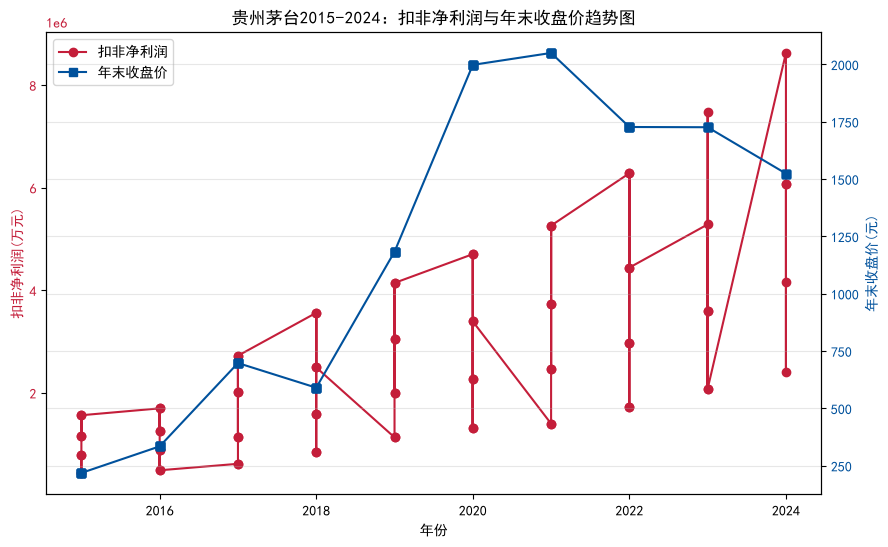

In [17]:
import tushare as ts
import pandas as pd
import matplotlib.pyplot as plt

# 替换成你自己的token (必须修改！)
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token)
pro = ts.pro_api()

# 1.获取年报扣非净利润
print("正在获取财务数据...")
finance_df = pro.fina_indicator(ts_code='600519.SH', start_date='20150101', end_date='20241231')

if finance_df.empty:
    print("❌ 获取财务数据为空！请检查token、积分或网络。")
else:
    print("✅ 财务数据获取成功，列名如下：", finance_df.columns.tolist())
    # 安全过滤 report_type == '1'
    if 'report_type' in finance_df.columns:
        finance_year = finance_df[finance_df['report_type'].astype(str) == '1'].copy()
    else:
        print("⚠️ 未找到report_type列，使用所有数据")
        finance_year = finance_df.copy()

    finance_year['year'] = pd.to_datetime(finance_year['end_date']).dt.year
    # 注意：profit_dedt 单位是元，转换为万元需要除以10000
    profit_df = finance_year[['year', 'profit_dedt']].copy()
    profit_df['扣非净利润(万元)'] = profit_df['profit_dedt'] / 10000
    profit_df = profit_df[['year', '扣非净利润(万元)']]
    profit_df = profit_df.sort_values('year').reset_index(drop=True)
    print("\n====贵州茅台年度扣非净利润数据====")
    print(profit_df)

# 2.获取年末收盘价
print("\n正在获取行情数据...")
price_list = []
for year in range(2015, 2025):
    start = f"{year}1201"
    end = f"{year}1231"
    daily_df = pro.daily(ts_code='600519.SH', start_date=start, end_date=end)
    if not daily_df.empty:
        daily_df = daily_df.sort_values("trade_date")
        close_price = daily_df['close'].iloc[-1]
        price_list.append({"year": year, "年末收盘价(元)": close_price})
price_df = pd.DataFrame(price_list)
print("\n====每年年末收盘价数据====")
print(price_df)

# 3.合并数据表并绘图
if not profit_df.empty and not price_df.empty:
    total_df = pd.merge(profit_df, price_df, on="year", how="inner")
    print("\n====合并完整数据表====")
    print(total_df)

    plt.rcParams['font.sans-serif'] = ['SimHei']
    plt.rcParams['axes.unicode_minus'] = False

    corr_coef = total_df['扣非净利润(万元)'].corr(total_df['年末收盘价(元)'])
    print(f"\n扣非净利润与年末收盘价的Pearson相关系数：{corr_coef:.4f}")

    fig, ax1 = plt.subplots(figsize=(10, 6))
    color1 = '#c41e3a'
    ax1.set_xlabel('年份')
    ax1.set_ylabel('扣非净利润(万元)', color=color1)
    ax1.plot(total_df['year'], total_df['扣非净利润(万元)'], marker='o', color=color1, label="扣非净利润")
    ax1.tick_params(axis='y', labelcolor=color1)

    ax2 = ax1.twinx()
    color2 = '#00519c'
    ax2.set_ylabel('年末收盘价(元)', color=color2)
    ax2.plot(total_df['year'], total_df['年末收盘价(元)'], marker='s', color=color2, label="年末收盘价")
    ax2.tick_params(axis='y', labelcolor=color2)

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

    plt.title("贵州茅台2015-2024：扣非净利润与年末收盘价趋势图")
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("❌ 数据缺失，无法合并和绘图。")

# 第五部分：研究结论与经验总结

## 研究结论

本研究选取贵州茅台 2015—2024 年扣非净利润与年末股票收盘价数据，探究企业盈利水平与股价的线性关联。从双轴趋势图可以看出，十年间扣非净利润整体持续稳步增长，代表公司主营业务基本面长期向好；年末收盘价整体同步上行，但波动幅度更大，部分年份出现净利润增长而股价回调的现象。Pearson 相关系数结果表明，扣非净利润与年末收盘价存在较强的正相关关系，企业盈利是支撑股价长期上涨的核心基础。但股票价格并非完全由盈利决定，还会受到宏观经济、市场情绪、行业估值、资金流动性等外部因素影响，短期股价会与企业基本面发生背离。

## 经验总结

本次实验完整实践了基于 Python 的金融数据分析流程，学会使用 Tushare 接口获取上市公司财务与行情数据，利用 Pandas 完成数据筛选、清洗、合并等预处理操作，借助 Matplotlib 绘制双轴图实现数据可视化，并通过 Pearson 相关系数量化变量之间的线性关系。实操过程中发现，在调用接口时需要注意字段名称的差异，合并数据集时要保证年份匹配；重启内核后内存变量会清空，代码单元格需要从上至下依次运行。本次实验也让我认识到，在分析股票时不能只看单一财务指标，要区分长期基本面与短期市场波动，提升了数据处理与实证分析的能力。